In [32]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
from sklearn.preprocessing import LabelEncoder
warnings.filterwarnings("ignore", category=FutureWarning)
from sklearn.preprocessing import StandardScaler
# Menggunakan StandardScaler untuk standardisasi

In [33]:
from apyori import apriori 
from mlxtend.frequent_patterns import apriori 
from mlxtend.frequent_patterns import association_rules 
import datetime

### LOADING DATASET

In [34]:
df = pd.read_excel('online_retail_II.xlsx')

In [35]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 525461 entries, 0 to 525460
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      525461 non-null  object        
 1   StockCode    525461 non-null  object        
 2   Description  522533 non-null  object        
 3   Quantity     525461 non-null  int64         
 4   InvoiceDate  525461 non-null  datetime64[ns]
 5   Price        525461 non-null  float64       
 6   Customer ID  417534 non-null  float64       
 7   Country      525461 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 32.1+ MB


In [36]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [37]:
df.isna().sum()

Invoice             0
StockCode           0
Description      2928
Quantity            0
InvoiceDate         0
Price               0
Customer ID    107927
Country             0
dtype: int64

In [38]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
Quantity,525461.0,10.337667,-9600.0,1.0,3.0,10.0,19152.0,107.42411
InvoiceDate,525461,2010-06-28 11:37:36.845017856,2009-12-01 07:45:00,2010-03-21 12:20:00,2010-07-06 09:51:00,2010-10-15 12:45:00,2010-12-09 20:01:00,NaN
Price,525461.0,4.688834,-53594.36,1.25,2.1,4.21,25111.09,146.126914
Customer ID,417534.0,15360.645478,12346.0,13983.0,15311.0,16799.0,18287.0,1680.811316


### EXPLORATORY DATA ANALYTICS (EDA)

In [39]:
cat_cols=df.select_dtypes(include=['object']).columns.tolist()
num_cols = df.select_dtypes(include=np.number).columns.tolist()
print("Categorical Variables:")
print(cat_cols)
print("Numerical Variables:")
print(num_cols)

Categorical Variables:
['Invoice', 'StockCode', 'Description', 'Country']
Numerical Variables:
['Quantity', 'Price', 'Customer ID']


Quantity
Skew : 36.04


c:\Users\asus\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1498: DeprecationWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):


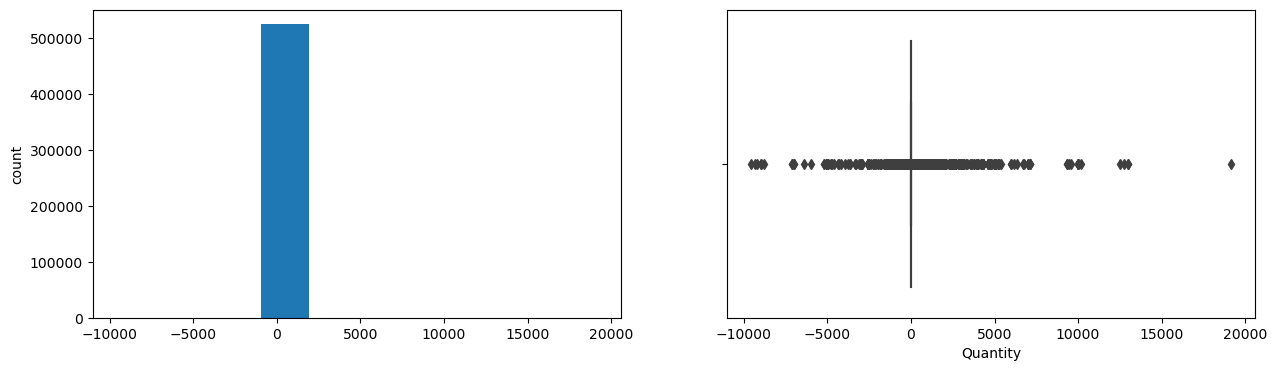

Price
Skew : -140.77


c:\Users\asus\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1498: DeprecationWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):


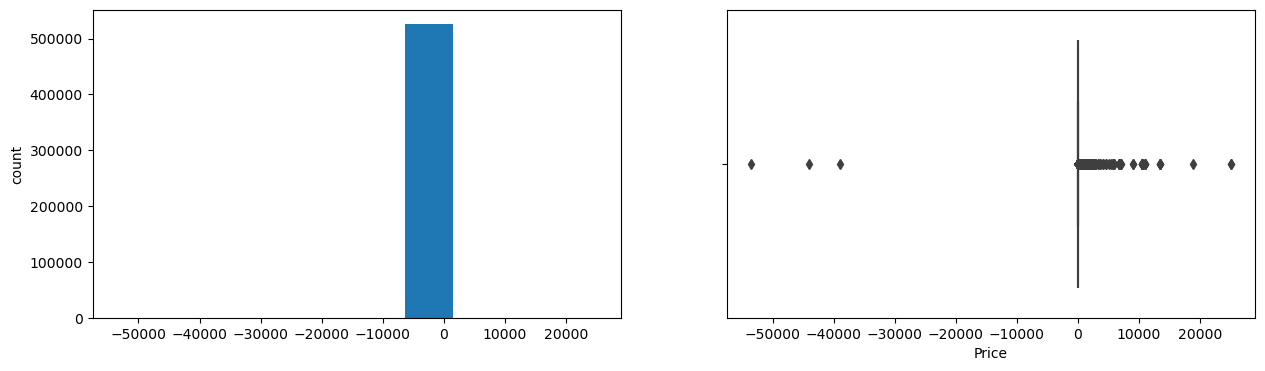

Customer ID
Skew : -0.02


c:\Users\asus\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1498: DeprecationWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):


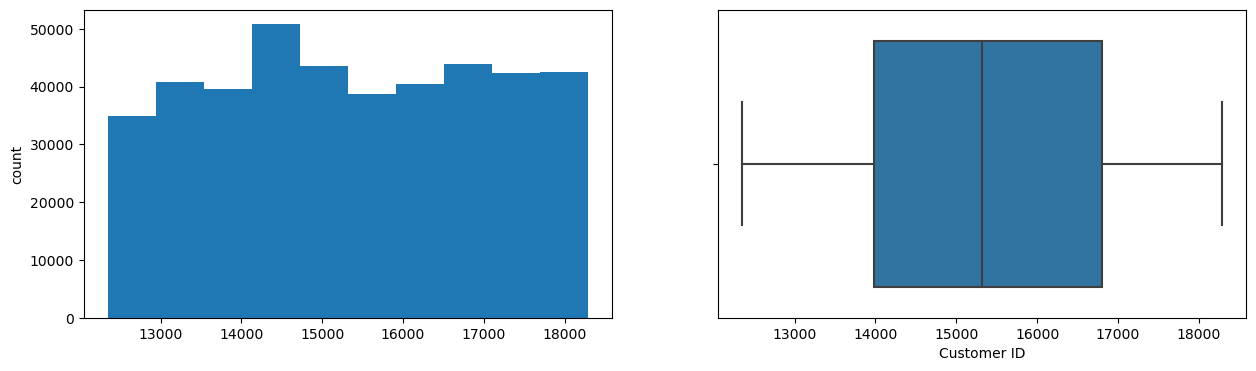

In [40]:
for col in num_cols:
    print(col)
    print('Skew :', round(df[col].skew(), 2))
    plt.figure(figsize = (15, 4))
    plt.subplot(1, 2, 1)
    df[col].hist(grid=False)
    plt.ylabel('count')
    plt.subplot(1, 2, 2)
    sns.boxplot(x=df[col])
    plt.show()

c:\Users\asus\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1498: DeprecationWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\asus\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1498: DeprecationWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\asus\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1498: DeprecationWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):


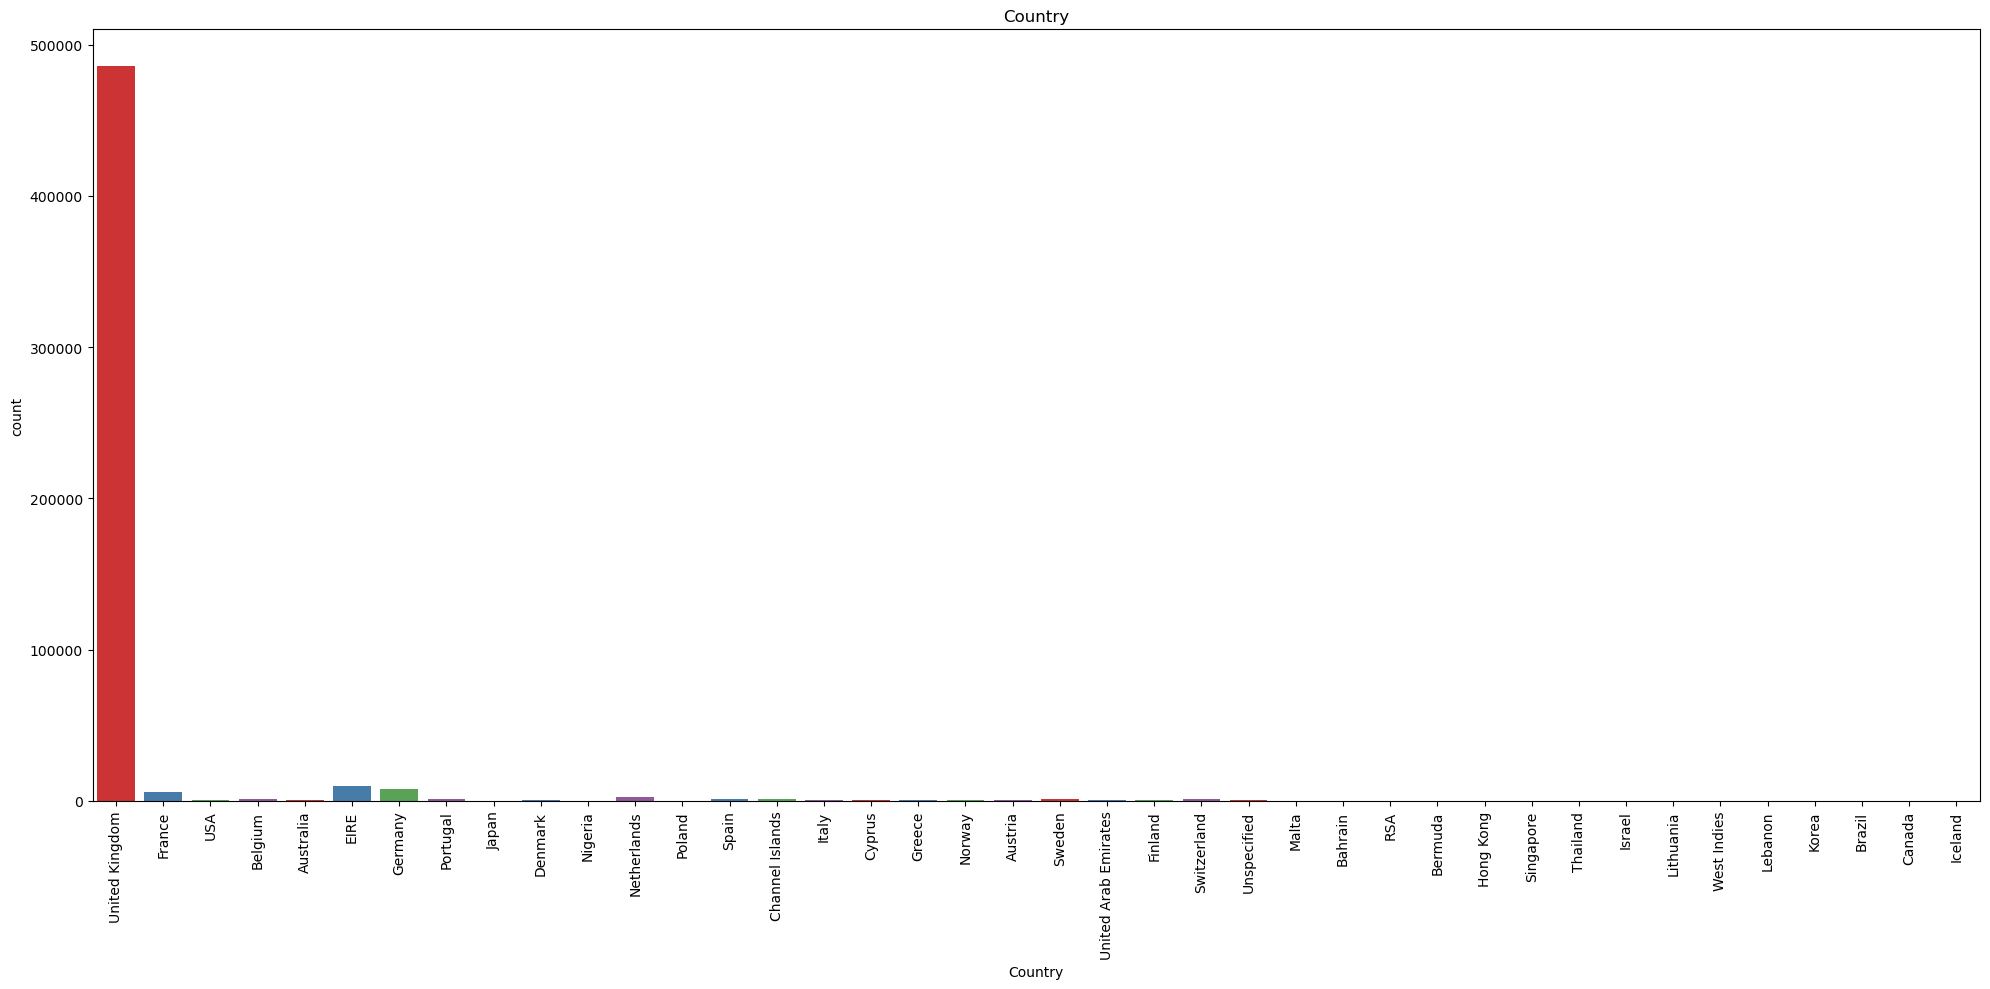

In [41]:
color_palette = sns.color_palette("Set1", len(cat_cols))
for i, column in enumerate(cat_cols, 1):
    if(column != 'InvoiceDate' and column != 'Description' and column != 'StockCode' and column!='Invoice'):
        plt.figure(figsize=(20, 10))
        sns.countplot(data=df, x=column, palette=color_palette)
        plt.xticks(rotation=90)
        plt.title(column)
        plt.tight_layout()
        plt.show()


In [105]:
next_max = df[df['Country'] == 'EIRE'].count().sum() / 7
next_max

8291.0

### Data Pre-Processing

In [42]:
df.drop(columns=["Customer ID"], axis=1, inplace=True)

In [43]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

In [ ]:
df['Invoice'] = df['Invoice'].astype('str')
df = df[~(df['Invoice'].str[0] == 'C' ) & ~(df['Invoice'].str[0] == 'A' )]
df['Invoice'] = df['Invoice'].astype('int')

In [79]:
df['StockCode'] = df['StockCode'].str.strip()

In [59]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,United Kingdom


In [77]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 440371 entries, 0 to 525460
Data columns (total 7 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      440371 non-null  int32         
 1   StockCode    440371 non-null  object        
 2   Description  438508 non-null  object        
 3   Quantity     440371 non-null  int64         
 4   InvoiceDate  440371 non-null  datetime64[ns]
 5   Price        440371 non-null  float64       
 6   Country      440371 non-null  object        
dtypes: datetime64[ns](1), float64(1), int32(1), int64(1), object(3)
memory usage: 25.2+ MB


In [114]:
df_subsets = df[df['Country'] == 'United Kingdom']
df_subsets = df_subsets.iloc[0:int(next_max)]
df_subsets[df['Country'] == 'United Kingdom'].count()

C:\Users\asus\AppData\Local\Temp\ipykernel_13588\2286147561.py:3: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df_subsets[df['Country'] == 'United Kingdom'].count()


Invoice        8291
StockCode      8291
Description    8277
Quantity       8291
InvoiceDate    8291
Price          8291
Country        8291
dtype: int64

In [115]:
basket = (df_subsets.groupby(['Invoice','StockCode']))['Quantity']
basket = basket.count().unstack().reset_index().fillna(0).set_index("Invoice")

In [116]:
basket.head()

StockCode,10002,10080,10109,10120,10125,10133,10134,10135,10138,11001,...,90188,90192,90203,90208,DCGS0004,DCGS0058,DCGS0068,DCGS0076,DOT,M
Invoice,,,,,,,,,,,,,,,,,,,,,
489434,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
489435,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
489436,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
489437,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
489438,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [117]:
def encode_units(x):
    if x <= 0:
        return 0
    if x >= 1:
        return 1


In [118]:
basket_sets = basket.applymap(encode_units)
basket_sets.head()

StockCode,10002,10080,10109,10120,10125,10133,10134,10135,10138,11001,...,90188,90192,90203,90208,DCGS0004,DCGS0058,DCGS0068,DCGS0076,DOT,M
Invoice,,,,,,,,,,,,,,,,,,,,,
489434,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
489435,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
489436,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
489437,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
489438,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


### Association Mining

In [ ]:
frequent_itemsets = apriori(basket_sets, min_support = 0.05, use_colnames=True)


c:\Users\asus\anaconda3\Lib\site-packages\mlxtend\frequent_patterns\fpcommon.py:161: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(


In [144]:
class Animals:
    def __init__(self,c_name,c_suara):
        self.__name = c_name
        self.__suara = c_suara
    def getName(self):
        return self.__name
    def setName(self,c_name):
        if(c_name != ""):
            self.__name = c_name
    def suara(self):
        return self.__suara

class Kucing(Animals):
    def __init__(self,c_name):
        super().__init__(c_name,"Meow")

kucing1 : Animals = Kucing("Jhontol")
print(kucing1.suara())
    

class var:
    value = None
    def __init__(self,val):
        self.value = val
x = var(15)
def add(x:var):
    x.value += 1
add(x)
print(x.value)

Meow
16


In [ ]:

frequent_itemsets.count()


support     52
itemsets    52
dtype: int64

In [ ]:
rules1 = association_rules(frequent_itemsets, metric="lift",min_threshold=1, num_itemsets=all)
rules1.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   antecedents         4 non-null      object 
 1   consequents         4 non-null      object 
 2   antecedent support  4 non-null      float64
 3   consequent support  4 non-null      float64
 4   support             4 non-null      float64
 5   confidence          4 non-null      float64
 6   lift                4 non-null      float64
 7   representativity    4 non-null      float64
 8   leverage            4 non-null      float64
 9   conviction          4 non-null      float64
 10  zhangs_metric       4 non-null      float64
 11  jaccard             4 non-null      float64
 12  certainty           4 non-null      float64
 13  kulczynski          4 non-null      float64
dtypes: float64(12), object(2)
memory usage: 580.0+ bytes


In [137]:
result1 = rules1[(rules1['lift'] >= 1) & (rules1['confidence'] >= 0.8)]
apr_result = result1.sort_values(by='confidence',ascending=False)
apr_result.head()

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
3,(22083),(22086),0.066158,0.175573,0.055980,0.846154,4.819398,1.0,0.044364,5.358779,0.848650,0.301370,0.813390,0.582497
0,(21231),(21232),0.078880,0.101781,0.066158,0.838710,8.240323,1.0,0.058129,5.568957,0.953889,0.577778,0.820433,0.744355
